In [34]:
from wpp import db
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
with db.get_con() as con:
    df_raw = con.sql("""
    select *
    from read_parquet('../data/wpp-home-panel-summary/weekly-patterns-home-panel-summary/*.parquet')
    where CENSUS_BLOCK_GROUP in (select GEOID from block_groups where CBSAFP = '35620');
    """).pl()

In [11]:
df_raw.head()

CENSUS_BLOCK_GROUP,DATE_RANGE_END,DATE_RANGE_START,ISO_COUNTRY_CODE,NUMBER_DEVICES_PRIMARY_DAYTIME,NUMBER_DEVICES_RESIDING,REGION
str,datetime[μs],datetime[μs],str,f64,f64,str
"""340390382012""",2025-11-03 00:00:00,2025-10-27 00:00:00,"""US""",24.0,21.0,"""NJ"""
"""340130008002""",2025-11-03 00:00:00,2025-10-27 00:00:00,"""US""",24.0,24.0,"""NJ"""
"""340311826004""",2025-11-03 00:00:00,2025-10-27 00:00:00,"""US""",24.0,37.0,"""NJ"""
"""340373749001""",2025-11-03 00:00:00,2025-10-27 00:00:00,"""US""",24.0,42.0,"""NJ"""
"""340030545004""",2025-11-03 00:00:00,2025-10-27 00:00:00,"""US""",24.0,10.0,"""NJ"""


In [40]:
df = df_raw.filter(
    pl.col("DATE_RANGE_START").dt.year() == 2025
).with_columns(
    ((pl.col("NUMBER_DEVICES_RESIDING") - pl.col("NUMBER_DEVICES_RESIDING").mean().over("CENSUS_BLOCK_GROUP")) 
    / pl.col("NUMBER_DEVICES_RESIDING").std().over("CENSUS_BLOCK_GROUP")).alias("Z_NUMBER_DEVICES_RESIDING")
)

In [47]:
lol = set(df["CENSUS_BLOCK_GROUP"][:5])

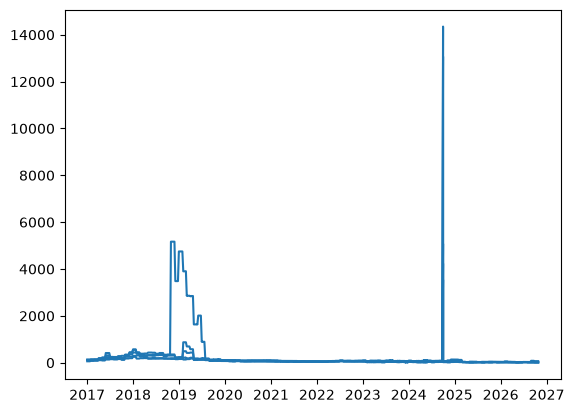

In [51]:
fig, ax = plt.subplots()
n_weeks = df["DATE_RANGE_START"].n_unique()
f = pl.len().over("CENSUS_BLOCK_GROUP") >= n_weeks * 0.8
for (cbg,), group in df_raw.filter(pl.col("CENSUS_BLOCK_GROUP").is_in(lol)).filter(f).group_by("CENSUS_BLOCK_GROUP"):
    group = group.sort("DATE_RANGE_START")
    x = group["DATE_RANGE_START"]
    y = group["NUMBER_DEVICES_RESIDING"]
    ax.plot(x, y, color="C0")

<Axes: xlabel='DATE_RANGE_START', ylabel='Z_NUMBER_DEVICES_RESIDING'>

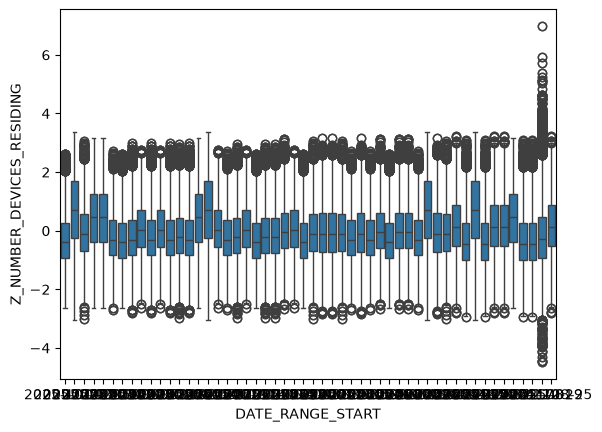

In [43]:
sns.boxplot(
    data=df.to_pandas(),
    x="DATE_RANGE_START",
    y="Z_NUMBER_DEVICES_RESIDING"
)

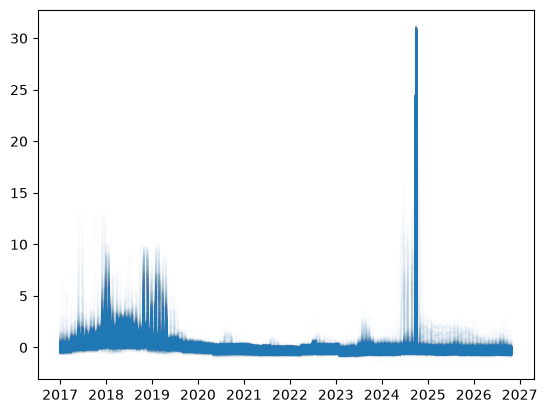

In [20]:
fig, ax = plt.subplots()
n_weeks = df["DATE_RANGE_START"].n_unique()
f = pl.len().over("CENSUS_BLOCK_GROUP") >= n_weeks * 0.8
for (cbg,), group in df.filter(f).group_by("CENSUS_BLOCK_GROUP"):
    group = group.sort("DATE_RANGE_START")
    x = group["DATE_RANGE_START"]
    y = group["NUMBER_DEVICES_RESIDING"]
    z = (y - y.mean()) / y.std()
    ax.plot(x, z, color="C0", alpha=.01)

In [13]:
group

CENSUS_BLOCK_GROUP,DATE_RANGE_END,DATE_RANGE_START,ISO_COUNTRY_CODE,NUMBER_DEVICES_PRIMARY_DAYTIME,NUMBER_DEVICES_RESIDING,REGION
str,datetime[μs],datetime[μs],str,f64,f64,str
"""360594060022""",2017-01-09 00:00:00,2017-01-02 00:00:00,"""US""",70.0,98.0,"""NY"""
"""360594060022""",2017-01-16 00:00:00,2017-01-09 00:00:00,"""US""",70.0,98.0,"""NY"""
"""360594060022""",2017-01-23 00:00:00,2017-01-16 00:00:00,"""US""",70.0,98.0,"""NY"""
"""360594060022""",2017-01-30 00:00:00,2017-01-23 00:00:00,"""US""",70.0,98.0,"""NY"""
"""360594060022""",2017-02-06 00:00:00,2017-01-30 00:00:00,"""US""",60.0,95.0,"""NY"""
…,…,…,…,…,…,…
"""360594060022""",2026-10-12 00:00:00,2026-10-05 00:00:00,"""US""",24.0,34.0,"""NY"""
"""360594060022""",2026-10-12 00:00:00,2026-10-05 00:00:00,"""US""",24.0,34.0,"""NY"""
"""360594060022""",2026-10-19 00:00:00,2026-10-12 00:00:00,"""US""",24.0,34.0,"""NY"""
